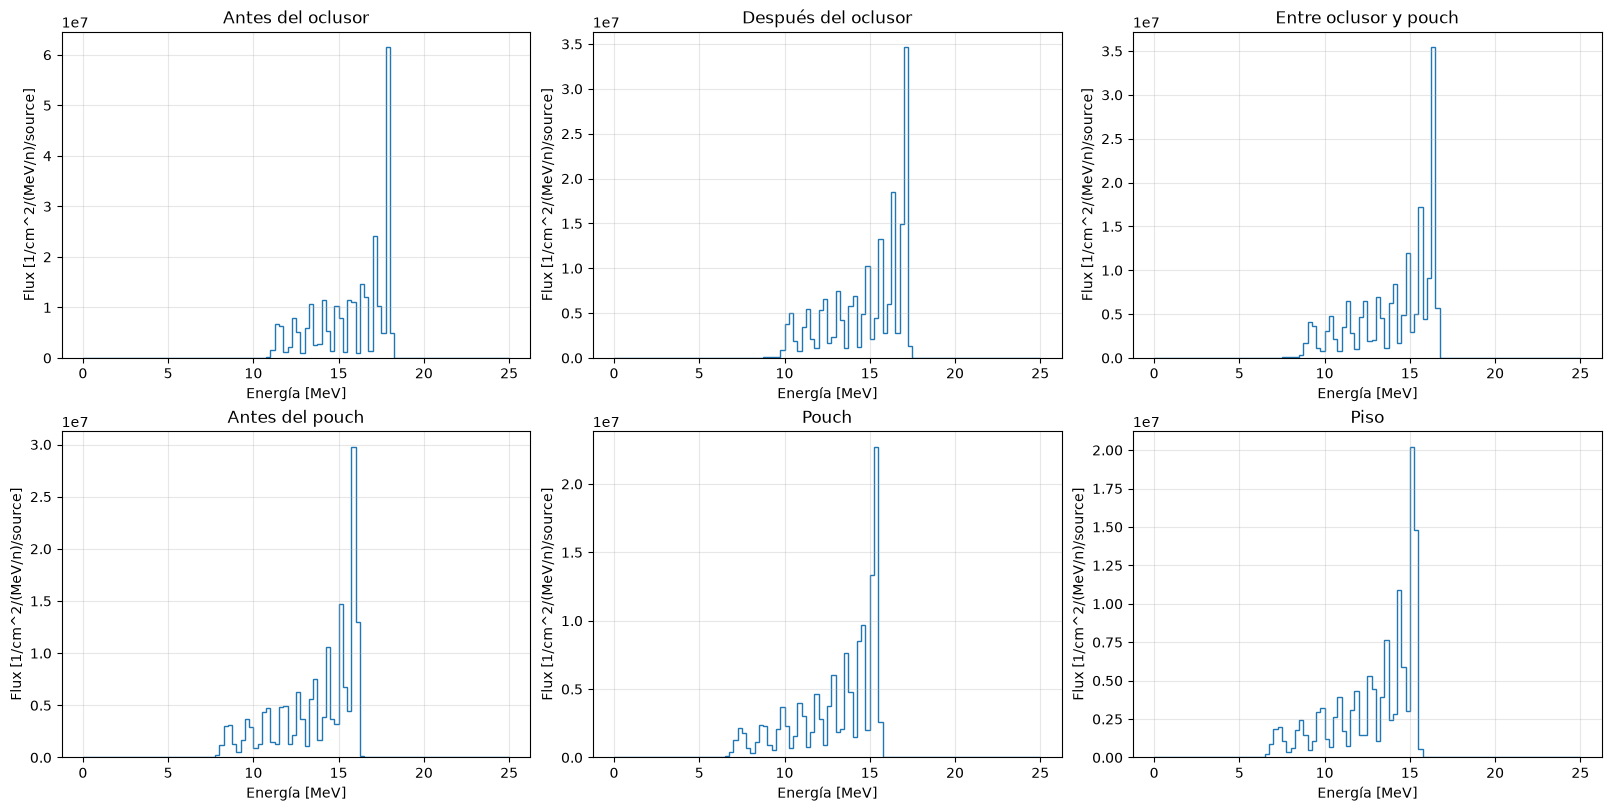

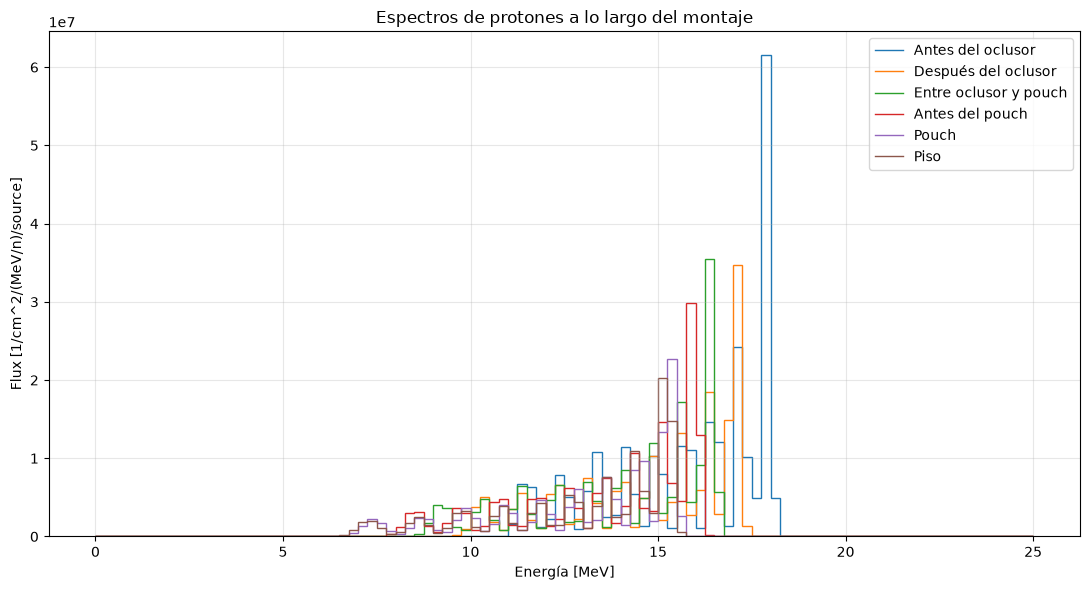

             Posición  Fluencia integrada [1/cm²/source]  Energía media [MeV]  Energía máxima [MeV]  Relativa al primer plano [%]
    Antes del oclusor                       6.219095e+07            15.785255                 18.25                    100.000000
  Después del oclusor                       4.595582e+07            14.825173                 17.75                     73.894716
Entre oclusor y pouch                       4.443520e+07            14.066800                 17.00                     71.449620
      Antes del pouch                       4.043567e+07            13.642144                 16.75                     65.018581
                Pouch                       3.233356e+07            13.018267                 16.00                     51.990783
                 Piso                       3.123586e+07            12.928880                 16.00                     50.225740


In [8]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

carpeta = Path('..') / 'out/'

archivos = {
    'Antes del oclusor': 'espectro_antes_oclusor.out',
    'Después del oclusor': 'espectro_despues_oclusor.out',
    'Entre oclusor y pouch': 'espectro_entre_oc_y_pouch.out',
    'Antes del pouch': 'espectro_antes_pouch.out',
    'Pouch': 'espectro_pouch.out',
    'Piso': 'espectro_piso.out',
}


def leer_espectro(ruta):
    if not ruta.is_file():
        raise FileNotFoundError(f'No encuentro {ruta.resolve()}')

    lineas = ruta.read_text(encoding='utf-8', errors='replace').splitlines()
    bloques = []
    ylabel = ''

    for i, linea in enumerate(lineas):
        s = linea.strip()
        if re.match(r'^y\s*:', s, flags=re.I):
            ylabel = s.split(':', 1)[1].strip()

        if not s.startswith('#'):
            continue

        encabezado = s.lstrip('#').split()
        nombres = [c.lower() for c in encabezado]
        if len(nombres) < 4 or nombres[:2] != ['e-lower', 'e-upper']:
            continue

        columnas_particulas = [k for k in range(2, len(nombres) - 1, 2)]
        columna = next((k for k in columnas_particulas if nombres[k].strip('(),') in ('proton', 'p')), None)
        if columna is None:
            if len(columnas_particulas) == 1:
                columna = columnas_particulas[0]
                print(f'Aviso: {ruta.name}: solo encontré la partícula {encabezado[columna]}.')
            else:
                raise ValueError(f'{ruta.name}: no encontré la columna proton en {encabezado}')

        datos = []
        for siguiente in lineas[i + 1:]:
            tokens = siguiente.strip().split()
            if not tokens:
                if datos:
                    break
                continue
            if tokens[0].startswith('#'):
                if datos:
                    break
                continue
            try:
                valores = [float(v.replace('D', 'E').replace('d', 'e')) for v in tokens]
            except ValueError:
                if datos:
                    break
                continue
            if len(valores) < columna + 2:
                if datos:
                    break
                continue
            datos.append((valores[0], valores[1], valores[columna], valores[columna + 1]))

        if datos:
            bloques.append((np.asarray(datos, dtype=float), ylabel, encabezado[columna]))

    if not bloques:
        candidatos = [(n, l.strip()) for n, l in enumerate(lineas, 1)
                      if re.search(r'e[-_ ]?lower|e[-_ ]?upper|axis\s*=', l, flags=re.I)]
        detalle = '\n'.join(f'  Línea {n}: {s[:140]}' for n, s in candidatos[:15])
        if not detalle:
            detalle = '\n'.join(f'  {n}: {l[:140]}' for n, l in enumerate(lineas[:25], 1))
        raise ValueError(
            f'{ruta.name}: no pude reconocer una tabla de espectro de energía.\n'
            f'Cabeceras o indicios detectados:\n{detalle}\n'
            'Revisá que el tally sea un espectro 1D (por ejemplo, axis = eng).'
        )

    if len(bloques) > 1:
        print(f'Aviso: {ruta.name}: encontré {len(bloques)} páginas y estoy usando la primera.')

    matriz, ylabel, particula = bloques[0]
    emin, emax, phi, err_rel = matriz.T
    if not np.all(np.isfinite(matriz)):
        raise ValueError(f'{ruta.name}: aparecen valores no finitos en la tabla')
    if not np.all(emax > emin):
        raise ValueError(f'{ruta.name}: los intervalos de energía no son válidos')
    if not np.all(np.diff(emin) >= 0):
        raise ValueError(f'{ruta.name}: la energía no está ordenada')

    ancho = emax - emin
    diferencial = bool(re.search(r'/(?:\s*MeV|\s*\(MeV)', ylabel, flags=re.I))
    peso = phi * ancho if diferencial else phi
    total = np.sum(peso)
    energia_media = np.sum(((emin + emax) / 2) * peso) / total if total > 0 else np.nan
    if not ylabel:
        print(f'Aviso: {ruta.name}: no encontré etiqueta del eje Y; verificá si la salida está dividida por MeV.')
    return {
        'E': (emin + emax) / 2,
        'emin': emin,
        'emax': emax,
        'fluencia': phi,
        'error': np.abs(phi * err_rel),
        'total': total,
        'energia_media': energia_media,
        'ylabel': ylabel or 'Fluencia (verificar unidades)',
        'diferencial': diferencial,
        'particula': particula,
    }


espectros = {nombre: leer_espectro(carpeta / archivo) for nombre, archivo in archivos.items()}

fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
for ax, (nombre, datos) in zip(axes.flat, espectros.items()):
    ax.stairs(datos['fluencia'], np.r_[datos['emin'], datos['emax'][-1]])
    ax.set(title=nombre, xlabel='Energía [MeV]', ylabel=datos['ylabel'])
    ax.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(11, 6))
for nombre, datos in espectros.items():
    plt.stairs(datos['fluencia'], np.r_[datos['emin'], datos['emax'][-1]], label=nombre)
plt.xlabel('Energía [MeV]')
plt.ylabel(next(iter(espectros.values()))['ylabel'])
plt.title('Espectros de protones a lo largo del montaje')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

modos = {d['diferencial'] for d in espectros.values()}
if len(modos) > 1:
    raise ValueError('Algunos tallies dan fluencia por MeV y otros por intervalo; revisá las unidades antes de comparar.')

primera_fluencia = next(iter(espectros.values()))['total']
resumen = pd.DataFrame([
    {
        'Posición': nombre,
        'Fluencia integrada [1/cm²/source]': d['total'],
        'Energía media [MeV]': d['energia_media'],
        'Energía máxima [MeV]': np.max(d['emax'][d['fluencia'] > 0]) if np.any(d['fluencia'] > 0) else np.nan,
        'Relativa al primer plano [%]': 100 * d['total'] / primera_fluencia if primera_fluencia > 0 else np.nan,
    }
    for nombre, d in espectros.items()
])
print(resumen.to_string(index=False))
